In [1]:
! git clone https://github.com/oliviapang/DS_4002_Project_2

Cloning into 'DS_4002_Project_2'...
remote: Enumerating objects: 27, done.
remote: Counting objects: 100% (27/27), done.
remote: Compressing objects: 100% (22/22), done.
remote: Total 27 (delta 2), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (27/27), 100.95 KiB | 1.28 MiB/s, done.
Resolving deltas: 100% (2/2), done.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [78]:
gas_data = pd.read_csv('/content/DS_4002_Project_2/DATA/GASREGW.csv')
oil_data = pd.read_excel('/content/DS_4002_Project_2/DATA/oil_data.xls')

In [80]:
# OIL DATA
# remove first two rows which contain only text details
oil_data = oil_data.drop([0,1], axis = 0)
# assign more useful column names
oil_data.columns = ['Date', 'Oil_Price']
# convert Date to datetime and Price to numeric (coercing any bad values)
oil_data['Date'] = pd.to_datetime(oil_data['Date'])
oil_data['Oil_Price'] = pd.to_numeric(oil_data['Oil_Price'], errors='coerce')
# drop missing values if any
oil_data = oil_data.dropna().sort_values('Date').reset_index(drop=True)

# GAS DATA
# assign more useful column names
gas_data.columns = ['Date', 'Gas_Price']
# convert Date to datetime and Price to numeric
gas_data['Date'] = pd.to_datetime(gas_data['Date'])
gas_data['Gas_Price'] = pd.to_numeric(gas_data['Gas_Price'], errors='coerce')
# drop missing values if any
gas_data = gas_data.dropna().sort_values('Date').reset_index(drop=True)

# merge datasets
merged_df = pd.merge_asof(gas_data, oil_data, on='Date', direction='nearest', tolerance=pd.Timedelta(days=3)

# drop any rows where matching failed
merged_df = merged_df.dropna().reset_index(drop=True)

print(merged_df.head())


--- Cleaned & Merged Data Head ---
        Date  Gas_Price  Oil_Price
0 1990-08-20      1.191      27.27
1 1990-08-27      1.245      30.08
2 1990-09-03      1.242      27.13
3 1990-09-10      1.252      29.67
4 1990-09-17      1.266      30.99


         Gas_Price    Oil_Price
count  1867.000000  1867.000000
mean      2.292889    53.036690
std       0.970493    29.126005
min       0.907000     3.320000
25%       1.263000    24.400000
50%       2.297000    51.690000
75%       3.102000    75.170000
max       5.006000   142.520000


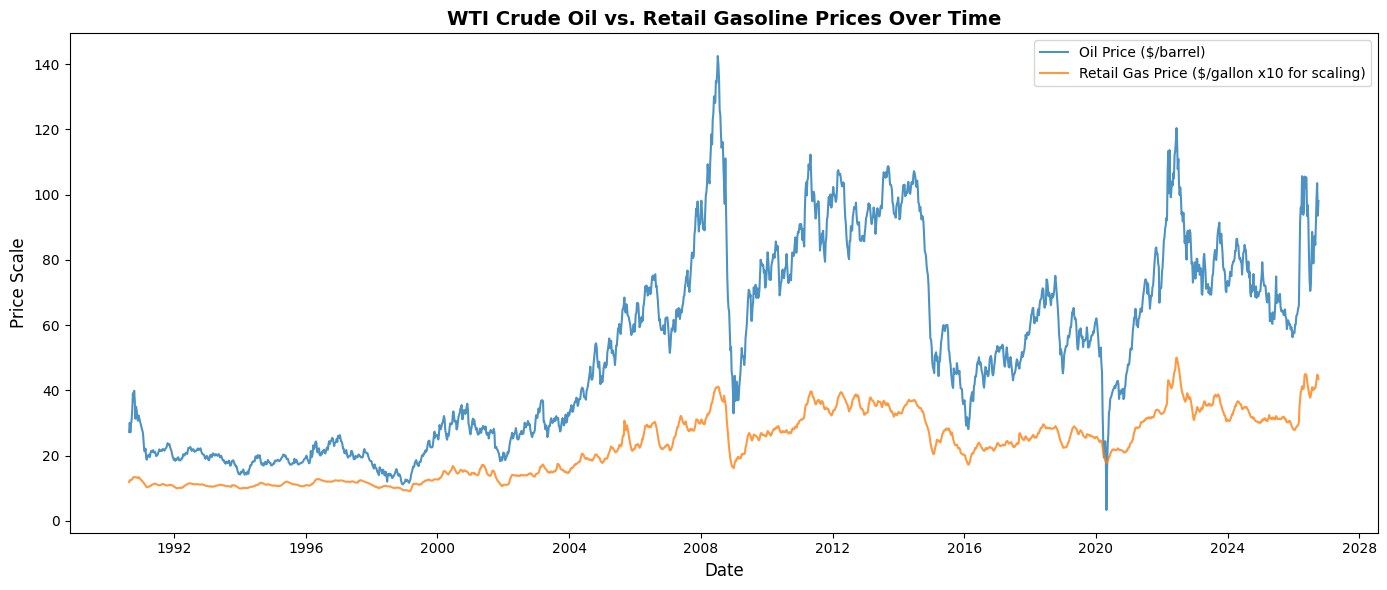

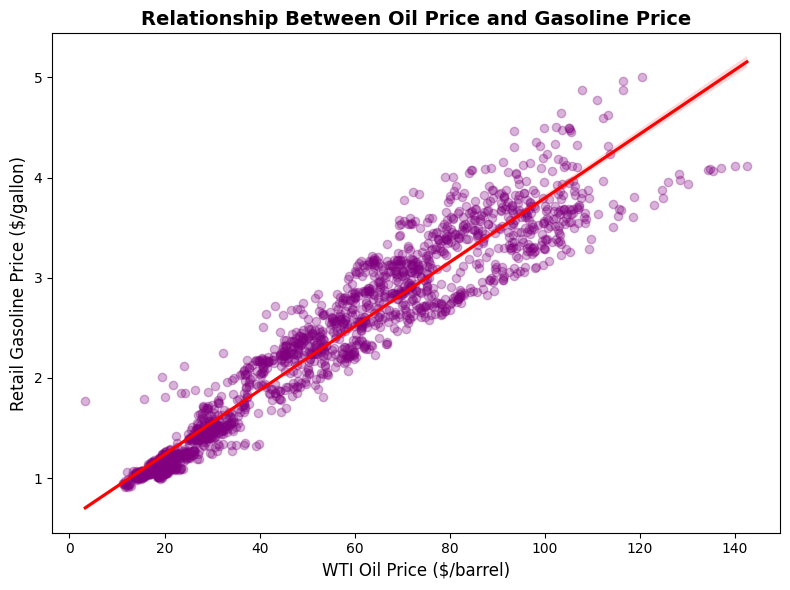

In [83]:
# summary statistics
print(merged_df[['Gas_Price', 'Oil_Price']].describe())

# Figure 1: Time Series Trends
plt.figure(figsize=(14, 6))
plt.plot(
    merged_df['Date'],
    merged_df['Oil_Price'],
    label='Oil Price ($/barrel)',
    color='tab:blue',
    alpha=0.8,
)
plt.plot(
    merged_df['Date'],
    merged_df['Gas_Price'] * 10,
    label='Retail Gas Price ($/gallon x10 for scaling)',
    color='tab:orange',
    alpha=0.8,
)
plt.title(
    'WTI Crude Oil vs. Retail Gasoline Prices Over Time',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price Scale', fontsize=12)
plt.legend()
plt.tight_layout()
plt.savefig('price_trends_timeseries.png', dpi=300)
plt.show()

# Figure 2: Scatter Plot with Regression Line
plt.figure(figsize=(8, 6))
sns.regplot(
    data=merged_df,
    x='Oil_Price',
    y='Gas_Price',
    scatter_kws={'alpha': 0.3, 'color': 'purple'},
    line_kws={'color': 'red'},
)
plt.title('Relationship Between Oil Price and Gasoline Price', fontsize=14, fontweight='bold')
plt.xlabel('WTI Oil Price ($/barrel)', fontsize=12)
plt.ylabel('Retail Gasoline Price ($/gallon)', fontsize=12)
plt.tight_layout()
plt.savefig('oil_gas_scatter.png', dpi=300)
plt.show()